# Dataset QC report: are the CellProfiler outlines good enough?

This report checks the whole dataset at once: the images, the cell outlines and the features. Each check gets a grade, and the scorecard in section 8 collects them. Notebook 02 (`02.qc.ipynb`) then checks each image and each cell, and marks the ones to remove.

**Question:** are the CellProfiler outlines good enough to use these single-cell profiles, or should we run CellProfiler again with other settings?

**Answer: the outlines are good enough, so we keep these profiles. One problem remains: in CL1, many touching nuclei are merged into one object. Notebook 02 flags these cells.**

- **Lighting is even** across each image. Blurred and over-exposed images are flagged one by one in notebook 02 (`02.qc.ipynb`).
- **Nuclei are not cut into pieces.** Only 0.2–0.4% (CL1) and 2.0–3.1% (CL2) of nuclei hold too little DNA, and both cell lines show the expected G1 and G2 DNA peaks.
- **CL1 has merged nuclei.** 14–28% of CL1 objects hold more DNA than one nucleus can. The scorecard does not test for this; section 6.3 shows it, and notebook 02 flags these cells.
- **Cell outlines are mostly good.** They hold 80–91% of the cell-body stain. CL2 outlines are slightly ragged at 1h and 4h.
- **Features are usable.** All 3,041 features have at most 0.1% missing values, and none is constant.

Cell numbers across the plate, replicate agreement and the TGFβ1 positive control are tested on the QCed profiles in `3.EDA` (notebooks 02, 03 and 01).

| Term | Meaning |
|---|---|
| Segmentation | Drawing the outline of each nucleus and cell. |
| Object | One nucleus, with its cell, as CellProfiler found it. Ideally, one object is one cell. |
| Site | One image in a well (9 per well). |
| Feature | One measurement of a cell, such as nucleus area. |
| Profile | All features of a cell, or their median over a well. |
| CL1, CL2 | The two cell lines, in columns 1–12 and 13–24. |
| DNA, RNA, AGP, ER, Mito | The 5 stains. AGP marks actin, Golgi and plasma membrane, so it shows the whole cell body. ER is the endoplasmic reticulum. |
| PASS, WARN, FAIL | Grades from the limits below. WARN means "look closer". |

## Setup

Run with `_run.sbatch` (about 200 GB of memory the first time). Slow steps are saved in `results/cache`; delete the folder to recompute them.

In [1]:
import json
import os
import pathlib
from concurrent.futures import ThreadPoolExecutor

n_threads = 16
os.environ["POLARS_MAX_THREADS"] = str(n_threads)
os.environ["OMP_NUM_THREADS"] = str(n_threads)

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from scipy import ndimage as ndi
from scipy.spatial import ConvexHull

In [2]:
seed = 0

profiles_dir = pathlib.Path("../0.prepare-profiles/results/single-cell-profiles").resolve(strict=True)
metadata_dir = pathlib.Path("../../data/metadata").resolve(strict=True)
cellprofiler_dir = pathlib.Path("../../data/sc-profiles/PALS-screen-profiles-v2").resolve(strict=True)
images_dir = pathlib.Path("../../../../project-data/PALS-screen-data").resolve(strict=True)

# results of this module; slow steps are saved in cache_dir, delete it to rebuild them
results_dir = pathlib.Path("results").resolve()
cache_dir = results_dir / "cache"
cache_dir.mkdir(parents=True, exist_ok=True)

# cells kept per well for the feature checks
cells_per_well = 100
# images per plate and cell line for the segmentation tests on the images
images_per_group = 12

# CellProfiler settings under test (2_analysis.cppipe, IdentifyPrimaryObjects)
nucleus_diameter_range = (30, 120)

channels = ["DNA", "RNA", "AGP", "ER", "Mito"]
channel_wavelength = {"DNA": 405, "RNA": 488, "AGP": 561, "Mito": 638, "ER": 730}

# fixed colors: one color per plate and per cell line in every figure
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
sequential = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
# figure style for print: figure sizes are the size on paper (7.2 in = full page width), text is 6-9 pt
sns.set_theme(style="ticks")
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6.5, "legend.title_fontsize": 7, "figure.titlesize": 9,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(50)

polars.config.Config

## Limits

We set these limits before we looked at the final results. Most are rules of thumb from image-based profiling.

In [3]:
# name: (pass limit, warn limit, "low" if lower is better else "high")
limits = {
    "Missing sites (%)": (0.5, 2, "low"),
    "Brightness change across the field (max/min)": (1.2, 1.4, "low"),
    "Nuclei near the upper size limit (%)": (0.5, 2, "low"),
    "Nuclei with too little DNA (%)": (10, 20, "low"),
    "Objects that are pieces of a cut nucleus (%)": (2, 5, "low"),
    "DNA signal without a nucleus object (%)": (2, 5, "low"),
    "AGP signal inside cell outlines (%)": (90, 75, "high"),
    "Cells with almost no cytoplasm (%)": (2, 5, "low"),
    "Median cell solidity": (0.85, 0.80, "high"),
}


def grade(name, value):
    """Return PASS, WARN or FAIL for one check."""
    pass_limit, warn_limit, direction = limits[name]
    sign = 1 if direction == "low" else -1
    if sign * value <= sign * pass_limit:
        return "PASS"
    return "WARN" if sign * value <= sign * warn_limit else "FAIL"


# filled in by each section and shown as a table at the end
scorecard = []


def score(name, value, group="All"):
    """Add one result to the scorecard."""
    scorecard.append({"check": name, "group": group, "value": round(float(value), 2), "grade": grade(name, value)})

## When would we run CellProfiler again?

We run CellProfiler again if two things are true. First, a segmentation check (6.2–6.5) fails in at least half of the 6 plate and cell line groups. Second, the image check in 6.4 confirms the cause.

## 1. Experiment design

Three plates (1h, 4h and 24h after treatment) share one layout. We check that every well has a clear label.

In [4]:
plate_files = {
    path.stem.split("_")[3]: path
    for path in sorted(profiles_dir.glob("*.parquet"))
}
plate_order = ["1h", "4h", "24h"]
plate_names = {time: plate_files[time].stem for time in plate_order}

platemap = pl.read_csv(metadata_dir / "platemap.csv", infer_schema_length=0).select(
    pl.col("Well").alias("Metadata_Well"),
    pl.col("Compound ID").alias("compound"),
    pl.col("Conc mM").cast(pl.Float64).round(2).alias("compound_stock_mM"),
)

ligands = (
    pl.read_csv(metadata_dir / "ligands.csv", infer_schema_length=0)
    .select(
        pl.col("destination well").alias("well"),
        pl.col("CellLine").alias("ligand_cell_line"),
        pl.col("Treatment").alias("ligand"),
        pl.col("Concentration final").alias("ligand_dose"),
    )
    .with_columns(
        (pl.col("well").str.slice(0, 1) + pl.col("well").str.slice(1).str.zfill(2)).alias("Metadata_Well")
    )
    .drop("well")
)

wells = (
    platemap.join(ligands, on="Metadata_Well", how="left")
    .with_columns(
        pl.col("Metadata_Well").str.slice(0, 1).alias("row"),
        pl.col("Metadata_Well").str.slice(1).cast(pl.Int64).alias("column"),
    )
    .with_columns(
        # the design is mirrored: columns 1-12 are CL1, columns 13-24 are CL2
        pl.when(pl.col("column") <= 12).then(pl.lit("CL1")).otherwise(pl.lit("CL2")).alias("cell_line"),
        (pl.col("row").is_in(["A", "P"]) | pl.col("column").is_in([1, 24])).alias("edge"),
    )
    .with_columns(
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.lit("compound"))
        .when(pl.col("ligand").is_not_null())
        .then(pl.lit("ligand"))
        .otherwise(pl.lit("control"))
        .alias("well_type"),
        pl.when(pl.col("compound") != "DMSO")
        .then(pl.col("compound") + "_" + pl.col("compound_stock_mM").cast(pl.String))
        .when(pl.col("ligand").is_not_null())
        .then(pl.col("ligand") + "_" + pl.col("ligand_dose"))
        .otherwise(pl.lit("DMSO"))
        .alias("treatment"),
    )
)

# the ligand file names the cell line, so it can test the column rule above
mismatch = wells.filter(pl.col("ligand").is_not_null() & (pl.col("ligand_cell_line") != pl.col("cell_line")))
if mismatch.height:
    raise ValueError(f"Cell line rule disagrees with ligands.csv in {mismatch.height} wells")

wells.group_by("cell_line", "well_type").agg(pl.len().alias("wells"), pl.col("treatment").n_unique().alias("treatments")).sort("cell_line", "well_type")

cell_line,well_type,wells,treatments
str,str,u32,u32
"""CL1""","""compound""",45,15
"""CL1""","""control""",129,1
"""CL1""","""ligand""",18,6
"""CL2""","""compound""",45,15
"""CL2""","""control""",129,1
"""CL2""","""ligand""",18,6


In [5]:
settings = []
for time in plate_order:
    params = json.loads((images_dir / plate_names[time] / "parameters.json").read_text())
    exposure = {c["Name"]: c["ExposureTime"] for c in params["channels_config"]}
    settings.append(
        {
            "plate": time,
            "cell line in parameters.json": params["cell_line"],
            "objective": params["objective"],
            **{f"{ch} exposure (ms)": exposure[f"Fluorescence {wl} nm Ex"] for ch, wl in channel_wavelength.items()},
        }
    )
pl.DataFrame(settings)

plate,cell line in parameters.json,objective,DNA exposure (ms),RNA exposure (ms),AGP exposure (ms),Mito exposure (ms),ER exposure (ms)
str,str,str,f64,f64,f64,f64,f64
"""1h""","""MDA-MB-231_wt_ko""","""20x (Olympus)""",5.0,7.0,80.0,20.0,100.0
"""4h""","""MDA-MB-231_wt_ko""","""20x (Olympus)""",5.0,7.0,80.0,20.0,100.0
"""24h""","""MDA-MB-231_wt_ko""","""20x (Olympus)""",5.0,7.0,90.0,20.0,200.0


**Result**

- 5 compounds and 2 ligands (TGFβ1, IL6), each at 3 doses, with 3 replicate wells per cell line and plate. Each cell line has 127 imaged DMSO control wells.
- **Cell line follows plate side** (CL1 in columns 1–12, CL2 in 13–24), so the two cannot be separated.
- **The 24h plate used longer exposures** for ER (200 vs 100 ms) and AGP (90 vs 80 ms). Compare each well only with the DMSO wells of its own plate.
- `parameters.json` names the cell line `MDA-MB-231_wt_ko`, which does not match the plate names (Panc1, hPSC). Which line is CL1 is not recorded.

## 2. Load the data

We load about 30 key columns for all 2.6 million cells, the image-level columns of every site, and 100 random cells per well (with all features).

In [6]:
key_columns = [
    "Metadata_Well", "Metadata_Site", "Metadata_Acquisition",
    "Nuclei_AreaShape_Area", "Nuclei_AreaShape_EquivalentDiameter", "Nuclei_AreaShape_Solidity",
    "Cells_AreaShape_Area", "Cells_AreaShape_Solidity", "Cytoplasm_AreaShape_Area",
    "Nuclei_Intensity_IntegratedIntensity_CorrDNA",
    "Nuclei_Location_Center_X", "Nuclei_Location_Center_Y",
    "Cells_Children_Cytoplasm_Count",
]
key_columns += [f"Nuclei_Intensity_MeanIntensity_Corr{ch}" for ch in channels]
key_columns += [f"Cytoplasm_Intensity_MeanIntensity_Corr{ch}" for ch in channels]
key_columns += [f"Cells_Intensity_MeanIntensity_Corr{ch}" for ch in channels]

cells = pl.concat(
    [pl.read_parquet(plate_files[t], columns=key_columns).with_columns(pl.lit(t).alias("plate")) for t in plate_order]
).join(wells.select("Metadata_Well", "cell_line", "well_type", "treatment"), on="Metadata_Well", how="left")
print(f"{cells.height:,} cells")

2,647,721 cells


In [7]:
all_columns = pl.scan_parquet(plate_files["1h"]).collect_schema().names()
image_columns = [
    c for c in all_columns
    if c.startswith(("Image_Count", "Image_ImageQuality", "Image_Threshold", "Image_ModuleError"))
    or c.startswith("Image_Intensity_MeanIntensity")
]

images = pl.concat(
    [
        pl.scan_parquet(plate_files[t])
        .select(["Metadata_Well", "Metadata_Site", "Metadata_Acquisition", *image_columns])
        .unique("Metadata_Acquisition")
        .collect()
        .with_columns(pl.lit(t).alias("plate"))
        for t in plate_order
    ]
).join(wells, on="Metadata_Well", how="left")
images.select(pl.len().alias("sites"))

sites
u32
10257


In [8]:
# measurements of cell biology; position, object numbers and neighbor IDs are bookkeeping
compartments = ("Cells_", "Cytoplasm_", "Nuclei_")
bookkeeping = ("Location", "Number", "Parent", "Children", "Center", "BoundingBox", "Orientation", "ClosestObjectNumber")
features = [
    c for c in all_columns
    if c.startswith(compartments) and not any(word in c for word in bookkeeping)
]
print(f"{len(features)} features out of {len(all_columns)} columns")


def build_sample(time):
    """Save a random sample of cells per well for one plate."""
    sample_path = cache_dir / f"cell-sample_{time}.parquet"
    if sample_path.exists():
        return
    table = pl.read_parquet(plate_files[time], columns=["Metadata_Well", "Metadata_Site", *features])
    table.filter(
        pl.int_range(pl.len()).shuffle(seed=seed).over("Metadata_Well") < cells_per_well
    ).write_parquet(sample_path)


for time in plate_order:
    build_sample(time)

cell_sample = pl.concat([pl.read_parquet(cache_dir / f"cell-sample_{t}.parquet") for t in plate_order])
print(f"cell sample: {cell_sample.height:,} cells")

3041 features out of 4054 columns
cell sample: 114,000 cells


## 3. Is the data complete?

**Pass if:** under 0.5% of sites are missing, and no CellProfiler step reports an error.

In [9]:
expected_sites = wells.filter(
    ~pl.col("Metadata_Well").is_in(["A01", "A24", "P01", "P24"])
).height * 9
completeness = (
    images.group_by("plate")
    .agg(pl.len().alias("sites"))
    .with_columns((100 * (1 - pl.col("sites") / expected_sites)).alias("missing_pct"))
    .sort("plate")
)
print(f"Expected sites per plate: {expected_sites} (380 wells; the 4 corner wells were not imaged)")

for time in plate_order:
    site_counts = images.filter(pl.col("plate") == time).group_by("Metadata_Well").agg(pl.len().alias("n"))
    print(time, "wells without 9 sites:", site_counts.filter(pl.col("n") != 9).rows())

error_columns = [c for c in images.columns if "ModuleError" in c]
print("Sites with a module error:", images.select(pl.any_horizontal(pl.col(error_columns) > 0).sum()).item())

score("Missing sites (%)", completeness["missing_pct"].max())
completeness

Expected sites per plate: 3420 (380 wells; the 4 corner wells were not imaged)
1h wells without 9 sites: []
4h wells without 9 sites: []
24h wells without 9 sites: [('N12', 8), ('N09', 8), ('M04', 8)]
Sites with a module error: 0


plate,sites,missing_pct
str,u32,f64
"""1h""",3420,0.0
"""24h""",3417,0.087719
"""4h""",3420,0.0


**Result: PASS.** All 3,420 sites per plate were processed, with no errors. Three sites on the 24h plate (wells M04, N09, N12) have no cells left. They lie in the CL1 area with few cells (see the cell count maps in `3.EDA/02.explore-metadata.ipynb`). In total, the data holds 2,647,721 cells.

## 4. Are the images sharp and not over-exposed?

Notebook 02 (`02.qc.ipynb`) now checks this for each image, and flags blurred and over-exposed images in the QC profile.

## 5. Is the lighting even across each image?

A cell's brightness should not depend on where it sits in the image.

**Pass if:** the brightest and dimmest parts of the image differ by less than 1.2-fold.

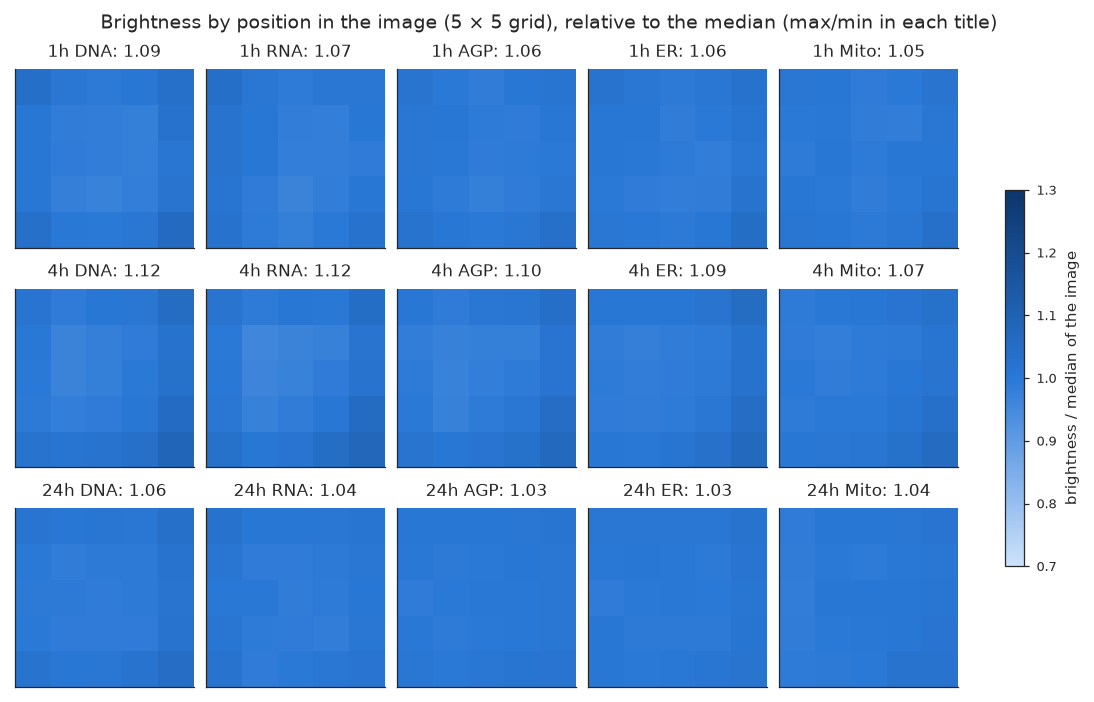

In [10]:
grid_bins = 5
image_size = 2500

position = cells.filter(pl.col("well_type") == "control").with_columns(
    (pl.col("Nuclei_Location_Center_X") * grid_bins / image_size).floor().clip(0, grid_bins - 1).alias("x_bin"),
    (pl.col("Nuclei_Location_Center_Y") * grid_bins / image_size).floor().clip(0, grid_bins - 1).alias("y_bin"),
)

ratios = []
fig, axes = plt.subplots(3, 5, figsize=(7.2, 4.6), constrained_layout=True)
for i, time in enumerate(plate_order):
    for j, ch in enumerate(channels):
        grid = (
            position.filter(pl.col("plate") == time)
            .group_by("y_bin", "x_bin")
            .agg(pl.col(f"Cells_Intensity_MeanIntensity_Corr{ch}").median().alias("value"))
            .sort("y_bin", "x_bin")["value"].to_numpy().reshape(grid_bins, grid_bins)
        )
        ratios.append({"plate": time, "channel": ch, "ratio": grid.max() / grid.min()})
        image = axes[i, j].imshow(grid / np.median(grid), cmap=sequential, vmin=0.7, vmax=1.3)
        axes[i, j].set(xticks=[], yticks=[], title=f"{time} {ch}: {grid.max() / grid.min():.2f}")
fig.colorbar(image, ax=axes, shrink=0.6, label="brightness / median of the image")
fig.suptitle("Brightness by position in the image (5 × 5 grid), relative to the median (max/min in each title)")
plt.show()

ratios = pl.DataFrame(ratios)
for row in ratios.group_by("channel").agg(pl.col("ratio").max()).sort("channel").iter_rows(named=True):
    score("Brightness change across the field (max/min)", row["ratio"], row["channel"])

**Result: PASS.** They differ by at most 1.12-fold, so the illumination correction works.

## 6. Are nuclei and cells outlined correctly?

This is the key section. Features are only right if the outlines are right. A nucleus cut in two becomes two false cells, and two merged nuclei become one false cell.

### 6.1 Look at the outlines

Control wells with a typical cell count. Red = AGP, green = ER, blue = DNA. White = nucleus outline, yellow = cell outline.

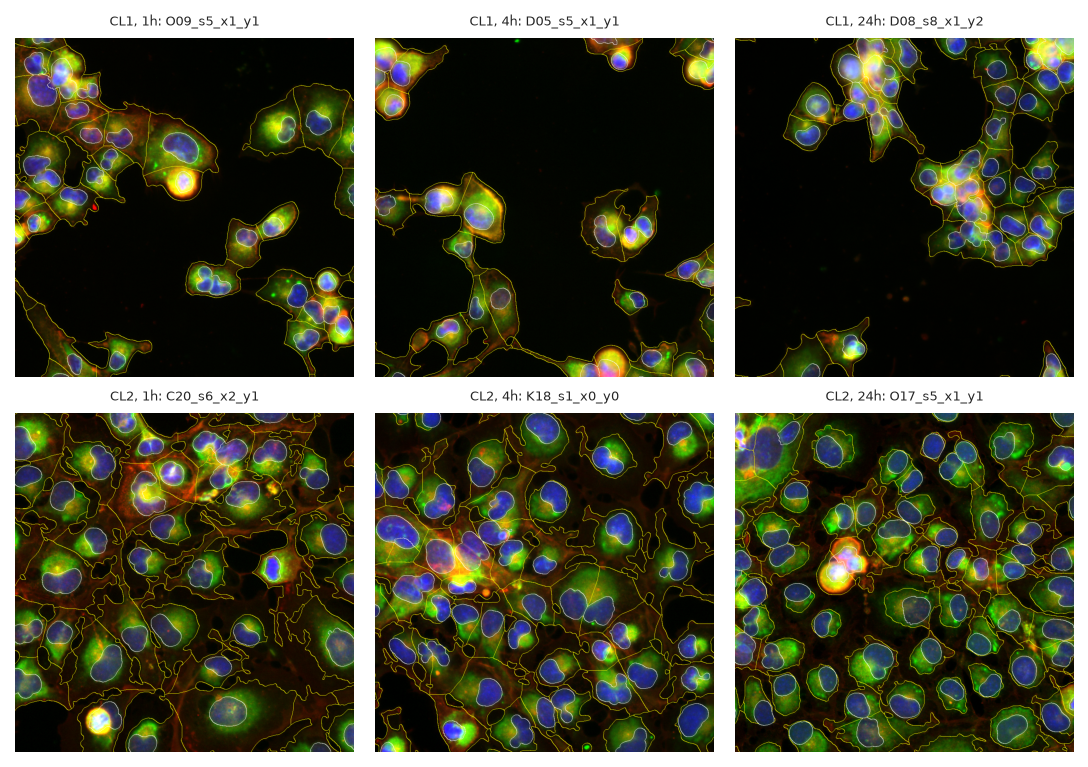

In [11]:
def plate_paths(time):
    """Folders with the masks and illumination functions of one plate."""
    plate = plate_names[time]
    run_dir = pathlib.Path((cellprofiler_dir / plate / "DONE").read_text().strip())
    return run_dir / "masks" / plate, run_dir / "illum" / plate


def read_image(time, site, channel):
    """Read one raw image, scaled from 0 to 1."""
    path = images_dir / plate_names[time] / f"{site}_Fluorescence_{channel_wavelength[channel]}_nm_Ex.tiff"
    return np.array(Image.open(path), dtype=float) / 65535


def read_mask(time, site, name):
    """Read one label image: 0 is background, each object has its own number."""
    return np.array(Image.open(plate_paths(time)[0] / f"{site}_{name}.tiff")).astype(np.int32)


def outlines(labels):
    """Pixels where one object meets another object or the background."""
    edge = np.zeros(labels.shape, bool)
    edge[:-1, :] |= labels[:-1, :] != labels[1:, :]
    edge[:, :-1] |= labels[:, :-1] != labels[:, 1:]
    return edge


def composite(time, site, crop=900):
    """Color image of the middle of one site, with outlines drawn on it."""
    start = (image_size - crop) // 2
    window = (slice(start, start + crop), slice(start, start + crop))

    def stretch(image):
        low, high = np.percentile(image[window], [1, 99.7])
        return np.clip((image[window] - low) / (high - low), 0, 1)

    rgb = np.dstack([stretch(read_image(time, site, ch)) for ch in ("AGP", "ER", "DNA")])
    rgb[outlines(read_mask(time, site, "CellsPaired")[window])] = (1, 1, 0)
    rgb[outlines(read_mask(time, site, "NucleiPaired")[window])] = (1, 1, 1)
    return rgb


def typical_site(time, line):
    """The control site with the cell count closest to the median of its group."""
    group = images.filter((pl.col("plate") == time) & (pl.col("cell_line") == line) & (pl.col("well_type") == "control"))
    target = group["Image_Count_Cells"].median()
    return group.sort((pl.col("Image_Count_Cells") - target).abs()).item(0, "Metadata_Acquisition")


fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.0), constrained_layout=True)
for i, line in enumerate(["CL1", "CL2"]):
    for j, time in enumerate(plate_order):
        site = typical_site(time, line)
        axes[i, j].imshow(composite(time, site))
        axes[i, j].set_title(f"{line}, {time}: {site}", fontsize=6)
        axes[i, j].axis("off")
plt.show()

**Result:** nuclei have one smooth outline each, and cell outlines reach the dim edge of the cell. In the dense CL1 clumps at 24h, we cannot see by eye whether each nucleus has its own outline (see 6.3).

### 6.2 Do nuclei fit the allowed size range?

CellProfiler removes objects outside 30–120 pixels in diameter.

**Pass if:** the size curve falls to zero before both limits, with under 0.5% of nuclei near the upper limit.

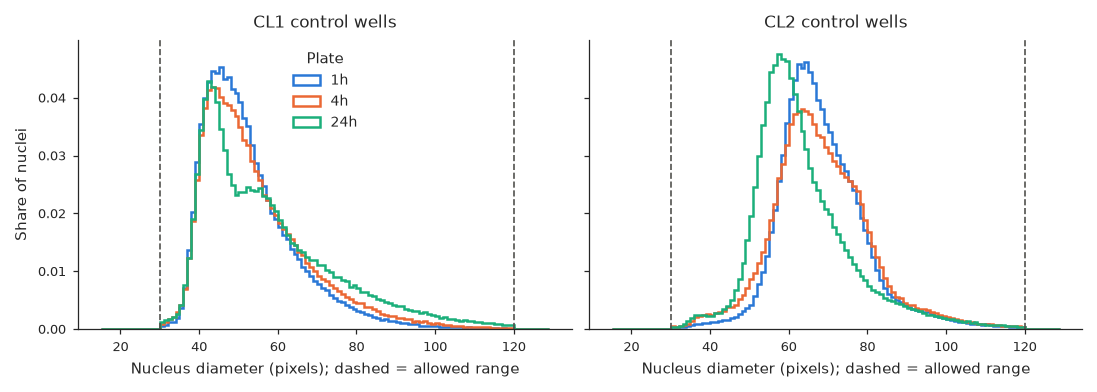

cell_line,plate,pct_near_upper_limit,median_diameter
str,str,f64,f64
"""CL1""","""1h""",0.07,50.1
"""CL1""","""24h""",0.48,53.6
"""CL1""","""4h""",0.13,51.2
"""CL2""","""1h""",0.25,66.9
"""CL2""","""24h""",0.33,61.3
"""CL2""","""4h""",0.32,67.1


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5), sharey=True, layout="constrained")
for ax, line in zip(axes, ["CL1", "CL2"]):
    for time in plate_order:
        values = cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line) & (pl.col("well_type") == "control"))
        ax.hist(
            values["Nuclei_AreaShape_EquivalentDiameter"].to_numpy(), bins=np.arange(15, nucleus_diameter_range[1] + 10, 1),
            density=True, histtype="step", lw=1.2, color=plate_colors[time], label=time,
        )
    for limit in nucleus_diameter_range:
        ax.axvline(limit, color="#52514e", ls="--", lw=0.8)
    ax.set(title=f"{line} control wells", xlabel="Nucleus diameter (pixels); dashed = allowed range")
axes[0].set_ylabel("Share of nuclei")
axes[0].legend(title="Plate")
plt.show()

near_limit = (
    cells.group_by("cell_line", "plate")
    .agg(
        (100 * (pl.col("Nuclei_AreaShape_EquivalentDiameter") > 0.95 * nucleus_diameter_range[1]).mean()).round(2).alias("pct_near_upper_limit"),
        pl.col("Nuclei_AreaShape_EquivalentDiameter").median().round(1).alias("median_diameter"),
    )
    .sort("cell_line", "plate")
)
for row in near_limit.iter_rows(named=True):
    score("Nuclei near the upper size limit (%)", row["pct_near_upper_limit"], f"{row['plate']} {row['cell_line']}")
near_limit

**Result: PASS.** At most 0.5% of nuclei are near the upper limit. The median diameter is 50–54 pixels in CL1 and 61–67 pixels in CL2. The CL1 24h curve has an extra shoulder at about 55–70 pixels, which merged nuclei would give.

### 6.3 Does each nucleus hold the right amount of DNA?

This is a built-in control. A healthy nucleus holds one DNA set (G1) or two (G2), so total DNA shows two peaks, the second at twice the first. A piece of a nucleus falls below the first peak. Two merged nuclei fall above the second.

**Pass if:** there are two clear peaks, and under 10% of nuclei hold less than 70% of the first peak.

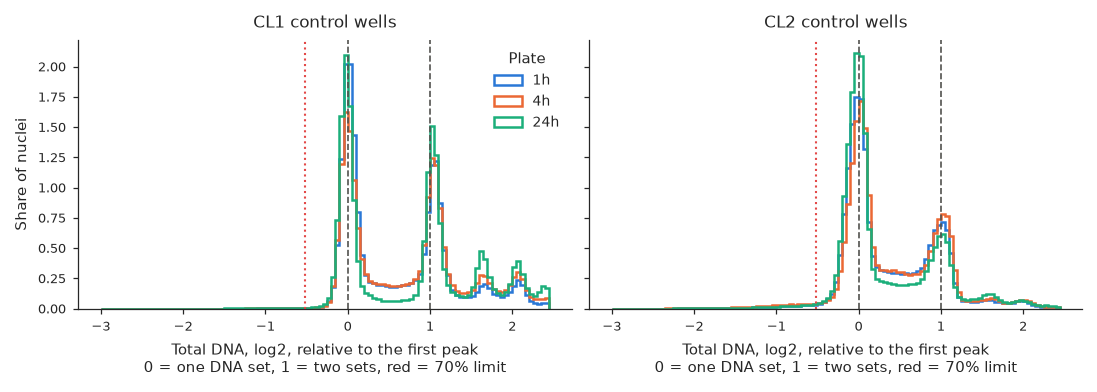

cell_line,plate,peak_log2,pct_too_little_dna
str,str,f64,f64
"""CL1""","""1h""",8.12,0.2
"""CL1""","""4h""",8.12,0.3
"""CL1""","""24h""",8.12,0.4
"""CL2""","""1h""",8.88,2.0
"""CL2""","""4h""",8.82,3.1
"""CL2""","""24h""",8.82,2.0


In [13]:
def g1_peak(values):
    """Position of the tallest peak of the DNA signal, on a log2 scale."""
    counts, bin_edges = np.histogram(values, bins=120, range=(5, 12))
    smooth = ndi.gaussian_filter1d(counts.astype(float), 1.5)
    return bin_edges[np.argmax(smooth)] + (bin_edges[1] - bin_edges[0]) / 2


fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5), sharey=True, layout="constrained")
low_dna = []
for ax, line in zip(axes, ["CL1", "CL2"]):
    for time in plate_order:
        values = np.log2(
            cells.filter((pl.col("plate") == time) & (pl.col("cell_line") == line) & (pl.col("well_type") == "control"))
            ["Nuclei_Intensity_IntegratedIntensity_CorrDNA"].to_numpy()
        )
        peak = g1_peak(values)
        share = 100 * np.mean(values < peak + np.log2(0.7))
        low_dna.append({"cell_line": line, "plate": time, "peak_log2": round(peak, 2), "pct_too_little_dna": round(share, 1)})
        ax.hist(values - peak, bins=np.arange(-3, 2.5, 0.05), density=True, histtype="step", lw=1.2, color=plate_colors[time], label=time)
    ax.axvline(0, color="#52514e", ls="--", lw=0.8)
    ax.axvline(1, color="#52514e", ls="--", lw=0.8)
    ax.axvline(np.log2(0.7), color="#e34948", ls=":", lw=1)
    ax.set(title=f"{line} control wells", xlabel="Total DNA, log2, relative to the first peak\n0 = one DNA set, 1 = two sets, red = 70% limit")
axes[0].set_ylabel("Share of nuclei")
axes[0].legend(title="Plate")
plt.show()

low_dna = pl.DataFrame(low_dna)
for row in low_dna.iter_rows(named=True):
    score("Nuclei with too little DNA (%)", row["pct_too_little_dna"], f"{row['plate']} {row['cell_line']}")
low_dna

**Result: PASS for cut nuclei, but CL1 has merged nuclei.**

- Few nuclei hold too little DNA: 0.2–0.4% in CL1 and 2.0–3.1% in CL2. Both lines show clear G1 and G2 peaks.
- **CL1 has extra peaks at 3 and 4 DNA sets.** No single nucleus holds 3 sets, but a G1 and a G2 nucleus in one outline do. Notebook 02 counts these objects: 13.7–27.5% of CL1 and 4.5–6.4% of CL2 objects hold more than 2.8 times the first peak.
- This check has no limit for high DNA, so the scorecard does not show this problem.

### 6.4 Are nuclei cut or lost?

We look at the masks of 72 control images. Two touching nuclei usually form a shape with a dent, while one nucleus cut in two forms a smooth shape. We also look for DNA signal with no nucleus on it (a lost nucleus).

**Pass if:** under 2% of objects are pieces of a cut nucleus, and under 2% of the DNA signal has no nucleus. **Control:** if the pieces are real, joining them must remove the low-DNA objects.

In [14]:
def measure_site(time, site, threshold, illumination):
    """Measure cut and lost nuclei and the signal captured by cell outlines in one site."""
    labels = read_mask(time, site, "NucleiPaired")
    cell_labels = read_mask(time, site, "CellsPaired")
    dna = read_image(time, site, "DNA") / illumination
    agp = read_image(time, site, "AGP")

    # join all touching objects into groups
    groups, n_groups = ndi.label(labels > 0, structure=np.ones((3, 3)))
    group_ids = np.arange(1, n_groups + 1)
    group_area = ndi.sum_labels(np.ones(labels.shape), groups, group_ids)
    group_dna = ndi.sum_labels(dna, groups, group_ids)
    pairs = np.unique(np.column_stack([labels[labels > 0], groups[labels > 0]]), axis=0)
    n_objects = np.bincount(pairs[:, 1], minlength=n_groups + 1)[1:]

    solidity = np.ones(n_groups)
    for index, box in enumerate(ndi.find_objects(groups)):
        if n_objects[index] > 1:
            y, x = np.nonzero(groups[box] == index + 1)
            solidity[index] = group_area[index] / ConvexHull(np.column_stack([y, x])).volume

    object_ids = np.arange(1, labels.max() + 1)
    object_area = ndi.sum_labels(np.ones(labels.shape), labels, object_ids)
    object_dna = ndi.sum_labels(dna, labels, object_ids)
    object_group = ndi.maximum(groups, labels, object_ids).astype(int)

    # DNA signal that no object covers, found with the threshold CellProfiler used for this site
    foreground = ndi.gaussian_filter(dna, 1.3488) > threshold
    unclaimed, n_unclaimed = ndi.label(foreground)
    has_object = np.zeros(n_unclaimed + 1, bool)
    has_object[np.unique(unclaimed[labels > 0])] = True
    claimed_ids = np.arange(1, n_unclaimed + 1)
    unclaimed_area = ndi.sum_labels(np.ones(labels.shape), unclaimed, claimed_ids)
    lost_area = unclaimed_area[~has_object[1:]]

    # share of the AGP signal above background that lies inside cell outlines
    signal = np.clip(agp - np.percentile(agp, 1), 0, None)

    base = {"plate": time, "site": site}
    summary = {
        **base,
        "objects": len(object_ids),
        "foreground_pixels": int(foreground.sum()),
        "lost_pixels": int(lost_area.sum()),
        "lost_large_objects": int((2 * np.sqrt(lost_area / np.pi) > nucleus_diameter_range[1]).sum()),
        "agp_inside_cells_pct": 100 * signal[cell_labels > 0].sum() / signal.sum(),
    }
    group_table = {
        "group": group_ids, "n_objects": n_objects, "area": group_area, "dna": group_dna, "solidity": solidity,
        "plate": [time] * n_groups, "site": [site] * n_groups,
    }
    object_table = {
        "area": object_area, "dna": object_dna, "group": object_group,
        "plate": [time] * len(object_ids), "site": [site] * len(object_ids),
    }
    return summary, group_table, object_table


def measure_group(args):
    """Measure one site, for use in a thread pool."""
    return measure_site(*args)


group_path = cache_dir / "nucleus-groups.parquet"
object_path = cache_dir / "nucleus-objects.parquet"
summary_path = cache_dir / "site-segmentation.parquet"

if not (group_path.exists() and object_path.exists() and summary_path.exists()):
    chosen = (
        images.filter(pl.col("well_type") == "control")
        .filter(pl.int_range(pl.len()).shuffle(seed=seed).over("plate", "cell_line") < images_per_group)
        .select("plate", "Metadata_Acquisition", "Image_Threshold_FinalThreshold_NucleiPaired")
    )
    jobs = []
    for time, site, threshold in chosen.iter_rows():
        jobs.append((time, site, threshold, np.load(plate_paths(time)[1] / "IllumDNA.npy")))
    with ThreadPoolExecutor(n_threads) as pool:
        results = list(pool.map(measure_group, jobs))
    pl.DataFrame([r[0] for r in results]).write_parquet(summary_path)
    pl.concat([pl.DataFrame(r[1]) for r in results]).write_parquet(group_path)
    pl.concat([pl.DataFrame(r[2]) for r in results]).write_parquet(object_path)

site_lookup = images.select(pl.col("Metadata_Acquisition").alias("site"), "plate", "cell_line", pl.col("Metadata_Well"))
site_segmentation = pl.read_parquet(summary_path).join(site_lookup, on=["site", "plate"])
nuclei_groups = pl.read_parquet(group_path).join(site_lookup, on=["site", "plate"])
nuclei_objects = pl.read_parquet(object_path).join(site_lookup, on=["site", "plate"])
print(site_segmentation.height, "sites,", nuclei_objects.height, "objects")

72 sites, 21574 objects


In [15]:
cut_table = (
    nuclei_groups.group_by("cell_line", "plate")
    .agg(
        pl.col("n_objects").sum().alias("objects"),
        pl.col("n_objects").filter((pl.col("n_objects") > 1) & (pl.col("solidity") >= 0.9)).sum().alias("objects_in_cut_nuclei"),
        (2 * (pl.col("area").filter((pl.col("n_objects") > 1) & (pl.col("solidity") >= 0.9)) / np.pi).sqrt()).median().round(1).alias("median_cut_nucleus_diameter"),
    )
    .with_columns((100 * pl.col("objects_in_cut_nuclei") / pl.col("objects")).round(1).alias("pct_cut"))
    .join(
        site_segmentation.group_by("cell_line", "plate").agg(
            (100 * pl.col("lost_pixels").sum() / pl.col("foreground_pixels").sum()).round(1).alias("pct_lost_signal"),
            pl.col("lost_large_objects").sum().alias("lost_objects_over_upper_limit"),
            pl.col("agp_inside_cells_pct").median().round(1).alias("agp_inside_cells_pct"),
        ),
        on=["cell_line", "plate"],
    )
    .sort("cell_line", "plate")
)
for row in cut_table.iter_rows(named=True):
    group = f"{row['plate']} {row['cell_line']}"
    score("Objects that are pieces of a cut nucleus (%)", row["pct_cut"], group)
    score("DNA signal without a nucleus object (%)", row["pct_lost_signal"], group)
cut_table

cell_line,plate,objects,objects_in_cut_nuclei,median_cut_nucleus_diameter,pct_cut,pct_lost_signal,lost_objects_over_upper_limit,agp_inside_cells_pct
str,str,i64,i64,f64,f64,f64,i64,f64
"""CL1""","""1h""",3611,70,73.1,1.9,0.7,1,87.6
"""CL1""","""24h""",2946,106,75.9,3.6,0.3,0,89.2
"""CL1""","""4h""",3461,107,79.6,3.1,0.6,1,90.2
"""CL2""","""1h""",2951,97,94.9,3.3,1.0,6,79.9
"""CL2""","""24h""",4984,212,85.7,4.3,1.1,8,90.7
"""CL2""","""4h""",3621,138,87.7,3.8,2.4,21,82.8


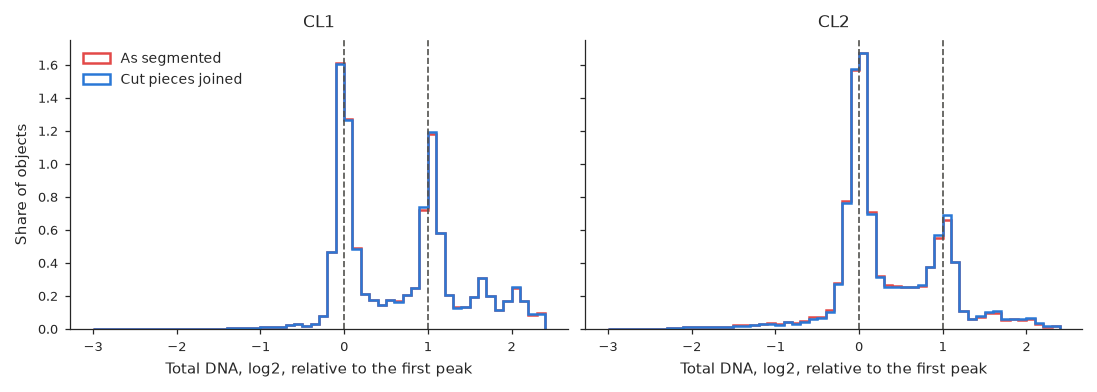

cell_line,pct_low_dna_as_segmented,pct_low_dna_after_joining
str,f64,f64
"""CL1""",1.3,1.3
"""CL2""",4.5,4.1


In [16]:
# positive control: join the pieces of cut nuclei, then repeat the DNA check
is_cut = (pl.col("n_objects") > 1) & (pl.col("solidity") >= 0.9)
is_touching = (pl.col("n_objects") > 1) & (pl.col("solidity") < 0.9)
repaired = pl.concat(
    [
        # single objects and joined cut nuclei count as one nucleus
        nuclei_groups.filter(~is_touching).select("cell_line", "plate", "dna", "area"),
        # touching nuclei with a dent stay as separate objects
        nuclei_objects.join(nuclei_groups.filter(is_touching), on=["site", "plate", "group"], how="semi")
        .select("cell_line", "plate", "dna", "area"),
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5), sharey=True, layout="constrained")
repair_rows = []
for ax, line in zip(axes, ["CL1", "CL2"]):
    before = np.log2(nuclei_objects.filter(pl.col("cell_line") == line)["dna"].to_numpy())
    after = np.log2(repaired.filter(pl.col("cell_line") == line)["dna"].to_numpy())
    peak = g1_peak(after)
    ax.hist(before - peak, bins=np.arange(-3, 2.5, 0.1), density=True, histtype="step", lw=1.2, color="#e34948", label="As segmented")
    ax.hist(after - peak, bins=np.arange(-3, 2.5, 0.1), density=True, histtype="step", lw=1.2, color="#2a78d6", label="Cut pieces joined")
    ax.axvline(0, color="#52514e", ls="--", lw=0.8)
    ax.axvline(1, color="#52514e", ls="--", lw=0.8)
    ax.set(title=line, xlabel="Total DNA, log2, relative to the first peak")
    repair_rows.append(
        {
            "cell_line": line,
            "pct_low_dna_as_segmented": round(100 * np.mean(before < peak + np.log2(0.7)), 1),
            "pct_low_dna_after_joining": round(100 * np.mean(after < peak + np.log2(0.7)), 1),
        }
    )
axes[0].legend()
axes[0].set_ylabel("Share of objects")
plt.show()
pl.DataFrame(repair_rows)

In [17]:
# the real nucleus size, after the pieces are joined
(
    repaired.with_columns((2 * (pl.col("area") / np.pi).sqrt()).alias("diameter"))
    .group_by("cell_line")
    .agg(
        *[pl.col("diameter").quantile(q).round(0).alias(f"p{int(100 * q)}") for q in (0.01, 0.05, 0.5, 0.95, 0.99)],
        (100 * (pl.col("diameter") < nucleus_diameter_range[0]).mean()).round(1).alias("pct_under_lower_limit"),
        (100 * (pl.col("diameter") > nucleus_diameter_range[1]).mean()).round(1).alias("pct_over_upper_limit"),
    )
    .sort("cell_line")
)

cell_line,p1,p5,p50,p95,p99,pct_under_lower_limit,pct_over_upper_limit
str,f64,f64,f64,f64,f64,f64,f64
"""CL1""",34.0,38.0,51.0,83.0,103.0,0.0,0.1
"""CL2""",36.0,47.0,64.0,91.0,108.0,0.0,0.2


**Result: WARN, but most "cut nuclei" are probably two touching nuclei.**

- 1.9–4.3% of objects form a smooth shape with a neighbor.
- Joining them does not change the share of low-DNA objects (CL1: 1.3% → 1.3%, CL2: 4.5% → 4.1%).
- The joined shapes are larger than one nucleus (median 73–95 pixels). So most are real nuclei that touch closely, not pieces.
- 0.3–2.4% of the DNA signal has no nucleus.

### 6.5 Do cell outlines follow the cell edge?

About two thirds of the features come from the cell and cytoplasm outlines.

**Pass if:**

- the median outline smoothness (solidity) is at least 0.85,
- at least 90% of the AGP stain lies inside cells,
- under 2% of cells have almost no cytoplasm, and
- DNA is at least 3 times brighter in the nucleus than in the cytoplasm.

In [18]:
cell_shape = (
    cells.with_columns(
        (pl.col("Cytoplasm_AreaShape_Area").fill_null(0) / pl.col("Cells_AreaShape_Area")).alias("cytoplasm_share")
    )
    .group_by("cell_line", "plate")
    .agg(
        pl.col("Cells_AreaShape_Solidity").median().round(3).alias("median_solidity"),
        pl.col("Cells_AreaShape_Area").median().alias("median_cell_area"),
        pl.col("Nuclei_AreaShape_Area").median().alias("median_nucleus_area"),
        (100 * pl.col("Cytoplasm_AreaShape_Area").is_null().mean()).round(2).alias("pct_no_cytoplasm"),
        (100 * (pl.col("cytoplasm_share") < 0.1).mean()).round(2).alias("pct_almost_no_cytoplasm"),
        (pl.col("Cells_AreaShape_Area") > 100_000).sum().alias("giant_cells"),
    )
    .sort("cell_line", "plate")
)
for row in cell_shape.iter_rows(named=True):
    group = f"{row['plate']} {row['cell_line']}"
    score("Median cell solidity", row["median_solidity"], group)
    score("Cells with almost no cytoplasm (%)", row["pct_almost_no_cytoplasm"], group)
for row in cut_table.iter_rows(named=True):
    score("AGP signal inside cell outlines (%)", row["agp_inside_cells_pct"], f"{row['plate']} {row['cell_line']}")
cell_shape

cell_line,plate,median_solidity,median_cell_area,median_nucleus_area,pct_no_cytoplasm,pct_almost_no_cytoplasm,giant_cells
str,str,f64,f64,f64,f64,f64,u32
"""CL1""","""1h""",0.883,7280.0,1968.0,0.03,0.08,32
"""CL1""","""24h""",0.894,6177.0,2257.0,0.22,0.85,0
"""CL1""","""4h""",0.894,6532.0,2056.0,0.04,0.14,1
"""CL2""","""1h""",0.83,13151.0,3517.0,0.01,0.03,54
"""CL2""","""24h""",0.881,9453.0,2955.0,0.05,0.14,33
"""CL2""","""4h""",0.843,12654.0,3536.0,0.02,0.05,31


In [19]:
# share of cells kept after CellProfiler removes the cells that touch the image border
images.with_columns((100 * pl.col("Image_Count_Cells") / pl.col("Image_Count_CellsPaired")).alias("kept")).group_by("cell_line", "plate").agg(
    pl.col("kept").median().round(1).alias("pct_cells_kept_after_border_filter")
).sort("cell_line", "plate")

cell_line,plate,pct_cells_kept_after_border_filter
str,str,f64
"""CL1""","""1h""",88.8
"""CL1""","""24h""",89.1
"""CL1""","""4h""",89.1
"""CL2""","""1h""",83.4
"""CL2""","""24h""",86.5
"""CL2""","""4h""",83.9


In [20]:
compartment_ratio = pl.DataFrame(
    [
        {
            "channel": ch,
            **{
                f"{line} {time}": round(
                    cells.filter((pl.col("cell_line") == line) & (pl.col("plate") == time))
                    .select((pl.col(f"Nuclei_Intensity_MeanIntensity_Corr{ch}") / pl.col(f"Cytoplasm_Intensity_MeanIntensity_Corr{ch}")).median())
                    .item(), 2,
                )
                for line in ("CL1", "CL2") for time in plate_order
            },
        }
        for ch in channels
    ]
)
print("Nucleus brightness divided by cytoplasm brightness (median per cell)")
compartment_ratio

Nucleus brightness divided by cytoplasm brightness (median per cell)


channel,CL1 1h,CL1 4h,CL1 24h,CL2 1h,CL2 4h,CL2 24h
str,f64,f64,f64,f64,f64,f64
"""DNA""",11.39,10.26,9.66,11.67,11.25,10.48
"""RNA""",1.76,1.81,1.93,1.65,1.6,1.74
"""AGP""",1.24,1.23,1.25,1.11,1.01,0.96
"""ER""",1.27,1.28,1.25,1.15,1.06,0.98
"""Mito""",1.43,1.46,1.48,1.28,1.16,1.08


**Result: mostly PASS, WARN for CL2.**

- Solidity is 0.88–0.89 in CL1 and 0.83–0.88 in CL2 (below 0.85 at 1h and 4h).
- 80–91% of the AGP stain lies inside cells. CL2 at 1h is lowest.
- Under 1% of cells have almost no cytoplasm, and DNA is 9.7–11.7 times brighter in the nucleus.
- 151 objects are giant (over 100,000 pixels). They are rare, but clearly wrong.
- The filter for cells on the image border removes 11–17% of cells, most in CL2, which has the largest cells.

## 7. Are the features usable?

**Pass if:** few values are missing, and no feature is constant.

In [21]:
null_counts = pl.concat(
    [pl.read_csv(path) for path in sorted(profiles_dir.glob("*_missing-values.csv"))]
).group_by("column").agg(pl.col("n_null").sum())
n_cells = cells.height
feature_nulls = null_counts.filter(pl.col("column").is_in(features)).with_columns((100 * pl.col("n_null") / n_cells).alias("pct_missing"))

spread = cell_sample.select(pl.col(features).std()).transpose(include_header=True, column_names=["std"])
constant = spread.filter((pl.col("std") == 0) | pl.col("std").is_null())["column"].to_list()

print(f"Features: {len(features)}")
print(f"Features with no missing values: {feature_nulls.filter(pl.col('n_null') == 0).height}")
print(f"Features with over 1% missing: {feature_nulls.filter(pl.col('pct_missing') > 1).height}")
print(f"Features with over 5% missing: {feature_nulls.filter(pl.col('pct_missing') > 5).height}")
print(f"Largest share missing: {feature_nulls['pct_missing'].max():.2f}%")
print(f"Constant features: {len(constant)}", constant[:6])
feature_nulls.sort("n_null", descending=True).head(5)

Features: 3041
Features with no missing values: 1989
Features with over 1% missing: 0
Features with over 5% missing: 0
Largest share missing: 0.10%
Constant features: 0 []


column,n_null,pct_missing
str,i64,f64
"""Cells_Correlation_K_CorrER_CorrDNA""",2575,0.097253
"""Cells_Correlation_K_CorrDNA_CorrER""",2575,0.097253
"""Cells_Correlation_Overlap_CorrDNA_CorrER""",2575,0.097253
"""Cells_Correlation_K_CorrMito_CorrDNA""",2496,0.09427
"""Cells_Correlation_Overlap_CorrDNA_CorrMito""",2496,0.09427


**Result: PASS.** All 3,041 features have at most 0.1% missing values, and none is constant. The preprocessing module (`2.preprocessing`) selects the features used downstream.

## 8. Scorecard

The worst result of each check across plates and cell lines.

In [22]:
results_table = pl.DataFrame(scorecard)
rank = {"PASS": 0, "WARN": 1, "FAIL": 2}
worst = (
    results_table.with_columns(
        pl.col("grade").replace_strict(rank, return_dtype=pl.Int64).alias("rank"),
        # the worst value is the highest for "lower is better" checks and the lowest for the others
        pl.when(pl.col("check").is_in([k for k, v in limits.items() if v[2] == "low"]))
        .then(pl.col("value"))
        .otherwise(-pl.col("value"))
        .alias("badness"),
    )
    .sort("badness", descending=True)
    .group_by("check", maintain_order=True)
    .agg(
        pl.col("value").first().alias("worst_value"),
        pl.col("group").first().alias("worst_group"),
        pl.col("grade").first(),
        (pl.col("grade") == "PASS").sum().alias("groups_passed"),
        pl.len().alias("groups"),
    )
)
order = {name: i for i, name in enumerate(limits)}
worst = worst.with_columns(pl.col("check").replace_strict(order, return_dtype=pl.Int64).alias("order")).sort("order").drop("order")
results_table.write_csv(results_dir / "quality-scorecard.csv")
worst

check,worst_value,worst_group,grade,groups_passed,groups
str,f64,str,str,u32,u32
"""Missing sites (%)""",0.09,"""All""","""PASS""",1,1
"""Brightness change across the field (max/min)""",1.12,"""DNA""","""PASS""",5,5
"""Nuclei near the upper size limit (%)""",0.48,"""24h CL1""","""PASS""",6,6
"""Nuclei with too little DNA (%)""",3.1,"""4h CL2""","""PASS""",6,6
"""Objects that are pieces of a cut nucleus (%)""",4.3,"""24h CL2""","""WARN""",1,6
"""DNA signal without a nucleus object (%)""",2.4,"""4h CL2""","""WARN""",5,6
"""AGP signal inside cell outlines (%)""",79.9,"""1h CL2""","""WARN""",2,6
"""Cells with almost no cytoplasm (%)""",0.85,"""24h CL1""","""PASS""",6,6
"""Median cell solidity""",0.83,"""1h CL2""","""WARN""",4,6
